<a href="https://colab.research.google.com/github/Noadori34/Project-data-science/blob/main/notebooks/05_validated_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Validated EfficientNet-B0 training

Research aim: compare full ultrasound images with kidney-focused (reference-mask) soft crops on exactly the same outer folds. Checkpoint selection happens on a distinct inner validation split, never the outer test partition.

Scientific caveat: This is annotation-assisted localization, not automatic kidney segmentation. The outer folds are independent of the inner checkpoint-selection procedure, but earlier experiments informed architecture and preprocessing choices, and group IDs are visual-similarity proxies, not verified patient IDs. Report accordingly.

In [6]:
%pip -q install timm scikit-learn pandas scipy pillow matplotlib
import os, sys, json, random, subprocess, hashlib
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageEnhance
import scipy.io as sio
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
import timm

REPO = Path('/content/Project-data-science')
if not (REPO/'.git').exists():
    subprocess.run(['git','clone','https://github.com/Noadori34/Project-data-science.git',str(REPO)],check=True)
os.chdir(REPO)
print('HEAD:',subprocess.check_output(['git','rev-parse','HEAD'],text=True).strip())
print('Torch:',torch.__version__,'GPU:',torch.cuda.is_available())

SEED=42
IMAGE_SIZE=224
EPOCHS=10
BATCH_SIZE=16
LR=1e-4
WEIGHT_DECAY=1e-2
PATIENCE=4
RUN_FOLDS = [0, 1, 2, 3, 4]
RUN_MODES = ["full", "kidney_focused"]
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RESULTS=REPO/'results'/'validated_cv'
RESULTS.mkdir(parents=True,exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
set_seed(SEED)


HEAD: ff3c6401a51e4e090467d372cc92244e0fd21272
Torch: 2.11.0+cpu GPU: False


##**Load previously committed nested split assignments**

In [7]:
SPLIT_FILE=REPO/'results/eda/nested_cv_splits.csv'
FOLD_FILE=REPO/'results/eda/folds_corrected.csv'
assert SPLIT_FILE.exists() and FOLD_FILE.exists(), 'Commit both CSV files before training.'
splits=pd.read_csv(SPLIT_FILE)
folds=pd.read_csv(FOLD_FILE)
required={'outer_fold','filename','diagnosis','group_id','split'}
assert required <= set(splits.columns), f'Missing columns: {required-set(splits.columns)}'
assert set(splits['split'])=={'train','validation','test'}
assert sorted(splits.outer_fold.unique().tolist())==[0,1,2,3,4]
assert len(folds)==1985 and folds.filename.nunique()==1985

for fold in range(5):
    d=splits[splits.outer_fold==fold]
    assert len(d)==1985 and d.filename.nunique()==1985
    sets={name:set(d.loc[d.split==name,'group_id']) for name in ['train','validation','test']}
    assert not (sets['train']&sets['validation'] or sets['train']&sets['test'] or sets['validation']&sets['test'])
    assert set(d.diagnosis.unique())=={0,1}
    assert (d.groupby('split').diagnosis.nunique()==2).all()
    expected=set(folds.loc[folds.fold==fold,'filename'])
    assert set(d.loc[d.split=='test','filename'])==expected
print('All five nested partitions verified')
print(splits.groupby(['outer_fold','split','diagnosis']).size().unstack(fill_value=0))


All five nested partitions verified
diagnosis                0    1
outer_fold split               
0          test         91  312
           train       286  974
           validation   73  249
1          test         97  291
           train       283  994
           validation   70  250
2          test         96  304
           train       291  976
           validation   63  255
3          test         78  323
           train       296  974
           validation   76  238
4          test         88  305
           train       284  987
           validation   78  243


##**Dataset, Crop and Image Transform**
For the kidney-focused condition, the annotated .mat mask supplies the kidney bounding box and a 25% context margin. An empty or unreadable mask raises an error rather than silently returning a full image. The same intensity normalization, input resolution and train-only augmentation are used in both conditions.

In [8]:
IMAGES=REPO/'bbdd_kidney/images'
MASKS=REPO/'bbdd_kidney/masks'
assert IMAGES.is_dir() and MASKS.is_dir()

def masked_crop(image, mask_path, pad_ratio=.25):
    mat=sio.loadmat(mask_path)
    candidates=[(k,np.asarray(v)) for k,v in mat.items() if not k.startswith('__') and isinstance(v,np.ndarray) and v.ndim==2]
    candidates=[(k,v) for k,v in candidates if v.shape==(image.height,image.width)]
    if len(candidates)!=1:
        raise ValueError(f'{mask_path.name}: expected one 2D aligned mask, found {[(k,x.shape) for k,x in candidates]}')
    mask=candidates[0][1]>0
    ys,xs=np.where(mask)
    if len(xs)==0: raise ValueError(f'Empty mask: {mask_path}')
    x0,x1=int(xs.min()),int(xs.max())+1
    y0,y1=int(ys.min()),int(ys.max())+1
    px=int((x1-x0)*pad_ratio);py=int((y1-y0)*pad_ratio)
    return image.crop((max(0,x0-px),max(0,y0-py),min(image.width,x1+px),min(image.height,y1+py)))

# Percentile intensity scaling is applied per image, before augmentation.
class PercentileNormalize:
    def __call__(self,img):
        a=np.asarray(img.convert('RGB'),dtype=np.float32)
        lo,hi=np.percentile(a,[1,99])
        a=np.clip((a-lo)/max(hi-lo,1e-6),0,1)
        return Image.fromarray((a * 255).astype(np.uint8))

train_transform=T.Compose([
    PercentileNormalize(),
    T.Resize((IMAGE_SIZE,IMAGE_SIZE)),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0,contrast=.15),
    T.ToTensor(),
    T.Lambda(lambda x: torch.clamp(x+torch.randn_like(x)*.02,0,1) if random.random()<.3 else x)
])
eval_transform=T.Compose([PercentileNormalize(),T.Resize((IMAGE_SIZE,IMAGE_SIZE)),T.ToTensor()])

class KidneyDataset(Dataset):
    def __init__(self,frame,mode,train):
        self.data=frame.reset_index(drop=True)
        self.mode=mode
        self.transform=train_transform if train else eval_transform
    def __len__(self): return len(self.data)
    def __getitem__(self,idx):
        row=self.data.iloc[idx]
        path=IMAGES/row.filename
        with Image.open(path) as im: image=im.convert('RGB')
        if self.mode=='kidney_focused':
            image=masked_crop(image,MASKS/f'{Path(row.filename).stem}.mat')
        tensor=self.transform(image)
        return tensor, int(row.diagnosis), row.filename

print('Dataset class ready')


Dataset class ready


##**Sanity Check Before Training**
The original five-fold study used MONAI intensity and augmentation transforms. This notebook uses a fixed, comparable torchvision implementation with analogous but not identical transforms, so its results should be treated as a new controlled experiment, not an exact numerical reproduction of the earlier runs. If exact reproduction is required, use the original MONAI transforms in both conditions and record package versions.

In [9]:
example=splits[(splits.outer_fold==0)&(splits.split=='train')].head(1)
for mode in RUN_MODES:
    x,y,fn=KidneyDataset(example,mode,False)[0]
    print(mode,fn,tuple(x.shape),y,float(x.min()),float(x.max()))


full 1.jpg (3, 224, 224) 1 0.0 1.0
kidney_focused 1.jpg (3, 224, 224) 1 0.0 1.0


##**Model, Matrix and Training function**


### Experimental Configuration - Frozen Protocol

Before executing the complete five-fold evaluation, we fixed the model architecture, preprocessing transformations, hyperparameters, random-seed policy, and evaluation criteria.

Both experiments use ImageNet-pretrained EfficientNet-B0 and the same nested cross-validation assignments. The only intended difference is the input representation: full ultrasound images versus kidney-focused images generated using expert-provided segmentation masks.

The best checkpoint is selected using inner-validation ROC-AUC. The outer test fold is evaluated only after checkpoint selection.

The configuration will not be modified based on the observed outer-fold results. This allows us to assess whether kidney-focused inputs provide a consistent improvement under the predefined experimental conditions.

The reported results will be interpreted as internal cross-validation estimates, not independent external clinical validation.

In [13]:

print("EXPERIMENT CONFIGURATION")
print("=" * 45)

print("Model: EfficientNet-B0 (ImageNet pretrained)")
print("Learning rate:", LR)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Base random seed:", SEED)
print("Device:", DEVICE)

print("\nEvaluation:")
print("Checkpoint selection: Inner-validation ROC-AUC")
print("Classification threshold: 0.5")

print("\nExperiments:")
print("1. Full ultrasound image")
print("2. Kidney-focused image")

print("\nOuter folds:", RUN_FOLDS)
print("Input modes:", RUN_MODES)


EXPERIMENT CONFIGURATION
Model: EfficientNet-B0 (ImageNet pretrained)
Learning rate: 0.0001
Weight decay: 0.01
Batch size: 16
Maximum epochs: 10
Early stopping patience: 4
Base random seed: 42
Device: cpu

Evaluation:
Checkpoint selection: Inner-validation ROC-AUC
Classification threshold: 0.5

Experiments:
1. Full ultrasound image
2. Kidney-focused image

Outer folds: [0, 1, 2, 3, 4]
Input modes: ['full', 'kidney_focused']


In [12]:

from google.colab import drive
from pathlib import Path

# Use a fresh mount location to avoid the existing /content/drive folder.
drive.mount("/content/gdrive")

# Save all training results directly to Google Drive.
RESULTS = Path(
    "/content/gdrive/MyDrive/kidney_project/validated_cv"
)

RESULTS.mkdir(parents=True, exist_ok=True)

print("Permanent results directory:", RESULTS)
print("Directory exists:", RESULTS.exists())

# Verify we can actually write to Google Drive.
test_file = RESULTS / "write_test.txt"
test_file.write_text("Persistence check")

assert test_file.read_text() == "Persistence check"
test_file.unlink()

print("PASS: Google Drive storage is writable")


Mounted at /content/gdrive
Permanent results directory: /content/gdrive/MyDrive/kidney_project/validated_cv
Directory exists: True
PASS: Google Drive storage is writable


In [7]:
import os

def make_model():
    model = timm.create_model(
        "efficientnet_b0",
        pretrained=True,
        num_classes=2
    )
    in_features = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, 2)
    )
    return model.to(DEVICE)


def loader(frame, mode, train):
    return DataLoader(
        KidneyDataset(frame, mode, train),
        batch_size=BATCH_SIZE,
        shuffle=train,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )


@torch.no_grad()
def predict(model, dl):
    model.eval()
    labels = []
    scores = []
    filenames = []

    for x, y, fn in dl:
        x = x.to(DEVICE)
        p = torch.softmax(model(x), dim=1)[:, 1].cpu().numpy()
        scores.extend(p.tolist())
        labels.extend(y.tolist())
        filenames.extend(fn)

    return pd.DataFrame({
        "filename": filenames,
        "true_label": labels,
        "probability": scores
    })


def measures(df, threshold=0.5):
    y = df.true_label.to_numpy()
    p = df.probability.to_numpy()
    yp = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, yp, labels=[0, 1]
    ).ravel()

    return {
        "auc": float(roc_auc_score(y, p)),
        "sensitivity": float(tp / (tp + fn)) if (tp + fn) else float("nan"),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "f1": float(f1_score(y, yp, zero_division=0)),
        "n": int(len(df)),
        "tp": int(tp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
    }


def train_one(outer_fold, mode):
    # Same seed per outer fold so full-image and kidney-focused runs
    # are paired as closely as possible.
    set_seed(SEED + outer_fold)

    subset = splits[splits.outer_fold == outer_fold]
    tr = subset[subset.split == "train"].copy()
    val = subset[subset.split == "validation"].copy()
    test = subset[subset.split == "test"].copy()

    m = make_model()
    opt = torch.optim.AdamW(
        m.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )
    sch = torch.optim.lr_scheduler.StepLR(
        opt,
        step_size=6,
        gamma=0.5
    )
    loss_fn = nn.CrossEntropyLoss()

    tr_loader = loader(tr, mode, True)
    val_loader = loader(val, mode, False)

    best = -1.0
    best_epoch = None
    stale = 0
    history = []

    ckpt = RESULTS / f"{mode}_outer{outer_fold}.pth"

    for epoch in range(1, EPOCHS + 1):
        m.train()
        running = 0.0

        for x, y, _ in tr_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            opt.zero_grad(set_to_none=True)
            loss = loss_fn(m(x), y)
            loss.backward()
            opt.step()

            running += loss.item() * len(y)

        sch.step()

        val_pred = predict(m, val_loader)
        val_auc = float(
            roc_auc_score(
                val_pred.true_label,
                val_pred.probability
            )
        )

        history.append({
            "fold": int(outer_fold),
            "mode": str(mode),
            "epoch": int(epoch),
            "train_loss": float(running / len(tr)),
            "inner_val_auc": float(val_auc),
        })

        print(
            f"{mode} fold={outer_fold} epoch={epoch} "
            f"loss={running/len(tr):.4f} inner_auc={val_auc:.4f}"
        )

        if val_auc > best + 1e-6:
            best = float(val_auc)
            best_epoch = int(epoch)
            stale = 0

            # Save only safe, simple Python values + model weights

            checkpoint_data = {
                "model": m.state_dict(),
                "fold": int(outer_fold),
                "mode": str(mode),
                "epoch": int(epoch),
                "inner_val_auc": float(val_auc),
            }

            # Write to a temporary file, then replace the checkpoint.
            # This reduces the risk of a partially written checkpoint.
            temp_ckpt = ckpt.with_suffix(".tmp")
            torch.save(checkpoint_data, temp_ckpt)
            os.replace(temp_ckpt, ckpt)

        else:
            stale += 1
            if stale >= PATIENCE:
                break

    # Outer test fold is touched only after checkpoint selection
    state = torch.load(
        ckpt,
        map_location=DEVICE,
        weights_only=True
    )
    m.load_state_dict(state["model"])

    test_pred = predict(m, loader(test, mode, False))
    test_pred["outer_fold"] = int(outer_fold)
    test_pred["mode"] = str(mode)
    test_pred["group_id"] = test_pred.filename.map(
        dict(zip(test.filename, test.group_id))
    )
    test_pred["selected_epoch"] = int(best_epoch)

    metric = measures(test_pred)
    metric.update({
        "outer_fold": int(outer_fold),
        "mode": str(mode),
        "selected_epoch": int(best_epoch),
        "inner_val_auc": float(best),
    })

    return test_pred, metric, pd.DataFrame(history)

##**Run Controlled Experiments**

In [13]:

import os
import pandas as pd

# Permanent location already mounted at /content/gdrive
RESULTS.mkdir(parents=True, exist_ok=True)

RUN_DIR = RESULTS / "individual_runs"
RUN_DIR.mkdir(parents=True, exist_ok=True)

RUN_FOLDS = [0, 1, 2, 3, 4]
RUN_MODES = ["full", "kidney_focused"]


def save_csv_safely(df, path):
    """Write CSV, then replace its destination."""
    temp_path = path.with_suffix(".tmp")
    df.to_csv(temp_path, index=False)
    os.replace(temp_path, path)


def run_paths(fold, mode):
    prefix = f"{mode}_outer{fold}"
    return {
        "predictions": RUN_DIR / f"{prefix}_predictions.csv",
        "metrics": RUN_DIR / f"{prefix}_metrics.csv",
        "history": RUN_DIR / f"{prefix}_history.csv",
        "complete": RUN_DIR / f"{prefix}_complete.txt",
        "checkpoint": RESULTS / f"{prefix}.pth",
    }


def is_complete(fold, mode):
    paths = run_paths(fold, mode)

    if not all(path.is_file() for path in paths.values()):
        return False

    try:
        predictions = pd.read_csv(paths["predictions"])
        metrics = pd.read_csv(paths["metrics"])

        expected = splits[
            (splits["outer_fold"] == fold) &
            (splits["split"] == "test")
        ]

        return (
            len(predictions) == len(expected)
            and predictions["filename"].is_unique
            and set(predictions["filename"]) == set(expected["filename"])
            and predictions["probability"].between(0, 1).all()
            and len(metrics) == 1
            and int(metrics.iloc[0]["outer_fold"]) == fold
            and metrics.iloc[0]["mode"] == mode
        )
    except (OSError, ValueError, KeyError, pd.errors.ParserError):
        return False


all_predictions = []
all_metrics = []
all_histories = []

for fold in RUN_FOLDS:
    for mode in RUN_MODES:
        paths = run_paths(fold, mode)

        if is_complete(fold, mode):
            print(f"RESUMING: Loading fold {fold}, {mode}")

            prediction = pd.read_csv(paths["predictions"])
            metric = pd.read_csv(paths["metrics"]).iloc[0].to_dict()
            history = pd.read_csv(paths["history"])

        else:
            print(f"\nTRAINING: fold {fold}, {mode}")

            prediction, metric, history = train_one(fold, mode)

            # Persist each successful evaluation independently
            save_csv_safely(prediction, paths["predictions"])
            save_csv_safely(pd.DataFrame([metric]), paths["metrics"])
            save_csv_safely(history, paths["history"])

            # Completion marker written LAST
            paths["complete"].write_text(
                f"fold={fold}\nmode={mode}\nstatus=complete\n"
            )

            print(f"SAVED: fold {fold}, {mode}")

        all_predictions.append(prediction)
        all_metrics.append(metric)
        all_histories.append(history)

        # Also update consolidated results after each model
        save_csv_safely(
            pd.concat(all_predictions, ignore_index=True),
            RESULTS / "out_of_fold_predictions.csv"
        )

        save_csv_safely(
            pd.DataFrame(all_metrics),
            RESULTS / "fold_metrics.csv"
        )

        save_csv_safely(
            pd.concat(all_histories, ignore_index=True),
            RESULTS / "training_history.csv"
        )

predictions_df = pd.concat(all_predictions, ignore_index=True)
metrics_df = pd.DataFrame(all_metrics)
history_df = pd.concat(all_histories, ignore_index=True)

print("\nCOMPLETE FIVE-FOLD RESULTS")
print(
    metrics_df[
        [
            "outer_fold", "mode", "auc",
            "sensitivity", "specificity",
            "f1", "selected_epoch"
        ]
    ]
)

print("\nSaved to:", RESULTS)


/tmp/ipykernel_2171/3744188052.py:25: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray((a*255).astype(np.uint8),'RGB')


full fold=0 epoch=1 loss=0.5463 inner_auc=0.6666


/tmp/ipykernel_2171/3744188052.py:25: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray((a*255).astype(np.uint8),'RGB')


full fold=0 epoch=2 loss=0.4509 inner_auc=0.7255


/tmp/ipykernel_2171/3744188052.py:25: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray((a*255).astype(np.uint8),'RGB')


...

kidney_focused fold=4 epoch=9 loss=0.1560 inner_auc=0.8630


/tmp/ipykernel_2171/3744188052.py:25: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray((a*255).astype(np.uint8),'RGB')


kidney_focused fold=4 epoch=10 loss=0.1306 inner_auc=0.8471


/tmp/ipykernel_2171/3744188052.py:25: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray((a*255).astype(np.uint8),'RGB')


   outer_fold            mode       auc  sensitivity  specificity        f1  \
0           0            full  0.816603     0.919872     0.439560  0.883077   
1           0  kidney_focused  0.810263     0.903846     0.461538  0.877138   
2           1            full  0.825982     0.883162     0.567010  0.871186   
3           1  kidney_focused  0.825982     0.859107     0.587629  0.860585   
4           2            full  0.833196     0.894737     0.552083  0.878837   
5           2  kidney_focused  0.827474     0.812500     0.666667  0.847341   
6           3            full  0.810510     0.783282     0.653846  0.839138   
7           3  kidney_focused  0.825593     0.866873     0.615385  0.884676   
8           4            full  0.835917     0.891803     0.590909  0.887439   
9           4  kidney_focused  0.849441     0.950820     0.454545  0.902022   

   selected_epoch  
0               7  
1               6  
2               8  
3               7  
4               7  
5         

In [14]:

print("Results directory:", RESULTS)

for file in sorted(RESULTS.rglob("*")):
    if file.is_file():
        print(
            file.relative_to(RESULTS),
            round(file.stat().st_size / 1024, 1),
            "KB"
        )


fold_metrics.csv 1.3 KB
full_outer0.pth 15953.8 KB
full_outer1.pth 15953.8 KB
full_outer2.pth 15953.8 KB
full_outer3.pth 15953.8 KB
full_outer4.pth 15953.8 KB
kidney_focused_outer0.pth 15957.4 KB
kidney_focused_outer1.pth 15957.4 KB
kidney_focused_outer2.pth 15957.4 KB
kidney_focused_outer3.pth 15957.4 KB
kidney_focused_outer4.pth 15957.4 KB
out_of_fold_predictions.csv 201.7 KB
training_history.csv 5.1 KB


In [15]:

# Final evaluation integrity audit

assert len(metrics_df) == 10
assert len(predictions_df) == 3970

assert not metrics_df.duplicated(
    ["outer_fold", "mode"]
).any()

assert not predictions_df.duplicated(
    ["filename", "mode"]
).any()

for mode in ["full", "kidney_focused"]:
    p = predictions_df[predictions_df["mode"] == mode]
    assert len(p) == 1985
    assert p["filename"].nunique() == 1985
    assert set(p["outer_fold"]) == set(range(5))
    assert p["probability"].between(0, 1).all()

full = predictions_df[
    predictions_df["mode"] == "full"
]

focused = predictions_df[
    predictions_df["mode"] == "kidney_focused"
]

paired = full.merge(
    focused,
    on=["filename", "outer_fold", "true_label"],
    suffixes=("_full", "_focused"),
    validate="one_to_one"
)

assert len(paired) == 1985
assert paired["filename"].nunique() == 1985

print("PASS: 10 model evaluations")
print("PASS: 3,970 out-of-fold predictions")
print("PASS: 1,985 paired test images")
print("PASS: No duplicated image evaluations")
print("PASS: Identical test assignments and labels")


PASS: 10 model evaluations
PASS: 3,970 out-of-fold predictions
PASS: 1,985 paired test images
PASS: No duplicated image evaluations
PASS: Identical test assignments and labels


##**Post-Training Analysis — Validated Five-Fold EfficientNet Comparison**

In [17]:

import pandas as pd
import numpy as np

# Use the saved results; do NOT rerun training.
metrics_df = pd.read_csv(RESULTS / "fold_metrics.csv")
predictions_df = pd.read_csv(RESULTS / "out_of_fold_predictions.csv")

# Mean and standard deviation across outer folds
summary = (
    metrics_df
    .groupby("mode")[["auc", "sensitivity", "specificity", "f1"]]
    .agg(["mean", "std"])
    .round(4)
)

print("FIVE-FOLD PERFORMANCE SUMMARY")
display(summary)

# Fair paired comparison: same outer folds
paired_folds = metrics_df.pivot(
    index="outer_fold",
    columns="mode",
    values="auc"
)

paired_folds["difference"] = (
    paired_folds["kidney_focused"] - paired_folds["full"]
)

print("\nPAIRED FOLD ROC-AUC COMPARISON")
display(paired_folds.round(4))

print(
    "\nMean paired AUC difference:",
    round(paired_folds["difference"].mean(), 4)
)
print(
    "SD of paired AUC differences:",
    round(paired_folds["difference"].std(), 4)
)


FIVE-FOLD PERFORMANCE SUMMARY


auc         sensitivity         specificity          \
                  mean     std        mean     std        mean     std   
mode                                                                     
full            0.8244  0.0108      0.8746  0.0528      0.5607  0.0781   
kidney_focused  0.8278  0.0140      0.8786  0.0518      0.5572  0.0948   

                    f1          
                  mean     std  
mode                            
full            0.8719  0.0193  
kidney_focused  0.8744  0.0212


PAIRED FOLD ROC-AUC COMPARISON


mode,full,kidney_focused,difference
outer_fold,,,
0,0.8166,0.8103,-0.0063
1,0.8260,0.8260,0.0000
2,0.8332,0.8275,-0.0057
3,0.8105,0.8256,0.0151
4,0.8359,0.8494,0.0135



Mean paired AUC difference: 0.0033
SD of paired AUC differences: 0.0104


In [18]:

from sklearn.metrics import roc_auc_score, confusion_matrix

print("POOLED OUT-OF-FOLD RESULTS")
print("Note: pooled AUC differs from the mean fold AUC.\n")

for mode in ["full", "kidney_focused"]:
    df = predictions_df[
        predictions_df["mode"] == mode
    ]

    y_true = df["true_label"].to_numpy()
    y_prob = df["probability"].to_numpy()
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    print(f"{mode}:")
    print("  Pooled ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
    print("  Sensitivity:", round(tp / (tp + fn), 4))
    print("  Specificity:", round(tn / (tn + fp), 4))
    print("  Confusion matrix:", [[tn, fp], [fn, tp]])
    print()


POOLED OUT-OF-FOLD RESULTS
Note: pooled AUC differs from the mean fold AUC.

full:
  Pooled ROC-AUC: 0.8195
  Sensitivity: 0.8736
  Specificity: 0.5578
  Confusion matrix: [[np.int64(251), np.int64(199)], [np.int64(194), np.int64(1341)]]

kidney_focused:
  Pooled ROC-AUC: 0.8209
  Sensitivity: 0.8788
  Specificity: 0.5578
  Confusion matrix: [[np.int64(251), np.int64(199)], [np.int64(186), np.int64(1349)]]



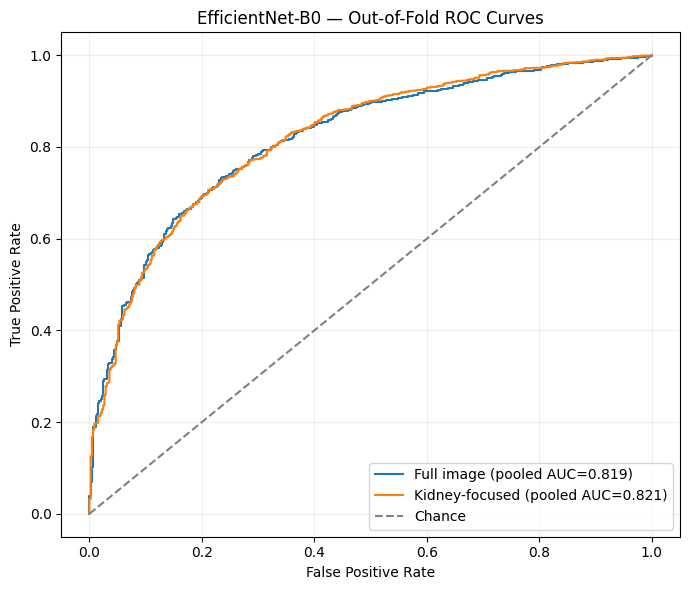

In [19]:
# ROC Curves


import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7, 6))

for mode, label in [
    ("full", "Full image"),
    ("kidney_focused", "Kidney-focused")
]:
    df = predictions_df[predictions_df["mode"] == mode]

    fpr, tpr, _ = roc_curve(
        df["true_label"],
        df["probability"]
    )

    auc = roc_auc_score(
        df["true_label"],
        df["probability"]
    )

    plt.plot(fpr, tpr, label=f"{label} (pooled AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--", color="gray", label="Chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EfficientNet-B0 — Out-of-Fold ROC Curves")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    RESULTS / "out_of_fold_roc_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [20]:
# Save Summary


summary.to_csv(RESULTS / "five_fold_summary.csv")
paired_folds.to_csv(RESULTS / "paired_fold_comparison.csv")

print("Analysis files saved to:", RESULTS)


Analysis files saved to: /content/Project-data-science/results/validated_cv
